In [2]:
# Cell 1: Environment Initialization & Setup
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from typing import Dict, Any, List, Tuple

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import GradientBoostingRegressor

# Ingest dataset and train production models
DATASET_PATH = 'data/SYNTHETIC_DATASET_100_CLEANED.csv'
df = pd.read_csv(DATASET_PATH)

ignore_cols = ['id', 'Sound', 'Mtrue', 'TEtrue', 'Mhat_v01', 'TEhat_v01', 'Soundhat_v01', 'Mat']
feature_cols = [c for c in df.columns if c not in ignore_cols]
X = df[feature_cols]

model_M = GradientBoostingRegressor(n_estimators=100, max_depth=3, learning_rate=0.08, random_state=42)
model_M.fit(X, df['Mtrue'])

model_TE = Pipeline([('scaler', StandardScaler()), ('reg', Ridge(alpha=5.0))])
model_TE.fit(X, df['TEtrue'])

model_Sound = Pipeline([('scaler', StandardScaler()), ('reg', Ridge(alpha=5.0))])
model_Sound.fit(X, df['Sound'])

def calculate_deterministic_gear_physics(inputs: Dict[str, Any]) -> Dict[str, Any]:
    mn = float(inputs['mn'])
    z1 = int(inputs['z1'])
    z2 = int(inputs['z2'])
    beta_deg = float(inputs['beta'])
    alpha_deg = float(inputs.get('alpha', 20.0))
    b = float(inputs['b'])
    T1 = float(inputs['T1'])
    n1 = float(inputs['n1'])
    
    beta_rad = np.radians(beta_deg)
    alpha_n_rad = np.radians(alpha_deg)
    alpha_t_rad = np.arctan(np.tan(alpha_n_rad) / np.cos(beta_rad))
    
    d1 = (mn * z1) / np.cos(beta_rad)
    d2 = (mn * z2) / np.cos(beta_rad)
    a = (d1 + d2) / 2.0
    v = (np.pi * d1 * n1) / 60000.0
    Ft = (2000.0 * T1) / d1
    cos_beta_b = np.cos(beta_rad) * np.cos(alpha_t_rad) / np.cos(alpha_n_rad)
    wt = Ft / (b * cos_beta_b)
    fm = (n1 * z1) / 60.0
    
    eps_beta = (b * np.sin(beta_rad)) / (np.pi * mn)
    eps_alpha = 1.88 - 3.2 * (1.0 / z1 + 1.0 / z2)
    eps_gamma = eps_alpha + eps_beta
    
    P = float(inputs.get('P', 0.0))
    if P <= 0.0:
        P = (T1 * n1) / 9550.0

    results = dict(inputs)
    results.update({
        'd1_mm': float(round(d1, 4)),
        'd2_mm': float(round(d2, 4)),
        'a': float(round(a, 3)),
        'v_mps': float(round(v, 3)),
        'Ft_N': float(round(Ft, 3)),
        'wt_N_per_mm': float(round(wt, 3)),
        'fm_Hz': float(round(fm, 2)),
        'eps_alpha': float(round(max(1.1, eps_alpha), 3)),
        'eps_beta': float(round(max(0.5, eps_beta), 3)),
        'eps_gamma': float(round(max(1.6, eps_gamma), 3)),
        'P': float(round(P, 2))
    })
    return results

def evaluate_forward_point(inputs: Dict[str, Any]) -> Tuple[float, float, float]:
    full_inputs = calculate_deterministic_gear_physics(inputs)
    sample = df[feature_cols].iloc[0].copy()
    for k, v in full_inputs.items():
        if k in sample:
            sample[k] = v
    X_eval = pd.DataFrame([sample])
    m = float(model_M.predict(X_eval)[0])
    te = float(model_TE.predict(X_eval)[0])
    s = float(model_Sound.predict(X_eval)[0])
    return m, te, s

print("Stage 3 base engine initialized and verified.")


Stage 3 base engine initialized and verified.


In [3]:
# Cell 2: Sensitivity Matrix Engine
def compute_parameter_sensitivity(base_inputs: Dict[str, Any], step_sizes: Dict[str, float] = None) -> pd.DataFrame:
    """
    Calculates localized finite-difference partial derivatives:
      d(Output) / d(Input_i)
    around the current operating setpoint.
    """
    if step_sizes is None:
        step_sizes = {
            'beta': 1.0,      # +1 deg
            'b': 2.0,         # +2 mm
            'Calpha': 1.0,    # +1 um
            'Cbeta': 1.0,     # +1 um
            'Q': 1.0,         # +1 ISO grade
            'T1': 5.0,        # +5 Nm
            'n1': 500.0,      # +500 rpm
            'mn': 0.25        # +0.25 mm
        }
        
    m_base, te_base, s_base = evaluate_forward_point(base_inputs)
    
    records = []
    for param, delta in step_sizes.items():
        if param not in base_inputs:
            continue
        
        perturbed = dict(base_inputs)
        perturbed[param] = base_inputs[param] + delta
        
        m_new, te_new, s_new = evaluate_forward_point(perturbed)
        
        dm = (m_new - m_base) / delta
        dte = (te_new - te_base) / delta
        ds = (s_new - s_base) / delta
        
        records.append({
            'Parameter': param,
            'Base_Value': base_inputs[param],
            'Delta_Tested': delta,
            'dM_dInput (µm/unit)': round(dm, 4),
            'dTE_dInput (µm/unit)': round(dte, 4),
            'dSound_dInput (dB/unit)': round(ds, 4)
        })
        
    return pd.DataFrame(records)

print("Sensitivity calculation engine compiled.")


Sensitivity calculation engine compiled.


In [4]:
# Cell 3: Plain-Language Design Translator
def generate_engineering_narrative(sens_df: pd.DataFrame) -> List[str]:
    """Translates mathematical gradients into clear design guidance."""
    statements = []
    for _, row in sens_df.iterrows():
        p = row['Parameter']
        dm = row['dM_dInput (µm/unit)']
        dte = row['dTE_dInput (µm/unit)']
        ds = row['dSound_dInput (dB/unit)']
        
        if p == 'beta':
            statements.append(
                f"• Helix Angle (β): +1.0° changes TE by {dte:+.3f} µm, Sound by {ds:+.2f} dB, and Misalignment by {dm:+.2f} µm."
            )
        elif p == 'b':
            statements.append(
                f"• Face Width (b): +1.0 mm changes TE by {dte:+.3f} µm, Sound by {ds:+.2f} dB, and Misalignment by {dm:+.2f} µm."
            )
        elif p == 'Calpha':
            statements.append(
                f"• Tip Relief (Cα): +1.0 µm adjustment shifts TE by {dte:+.3f} µm and Sound by {ds:+.2f} dB."
            )
        elif p == 'Cbeta':
            statements.append(
                f"• Crowning (Cβ): +1.0 µm crowning shifts TE by {dte:+.3f} µm and Misalignment by {dm:+.2f} µm."
            )
        elif p == 'Q':
            statements.append(
                f"• Quality Grade (Q): Degrading by +1 ISO grade shifts TE by {dte:+.3f} µm and Sound by {ds:+.2f} dB."
            )
        elif p == 'T1':
            statements.append(
                f"• Torque (T1): +10 Nm added load alters Misalignment by {(dm*10):+.2f} µm and TE by {(dte*10):+.3f} µm."
            )
    return statements

print("Engineering narrative generator compiled.")


Engineering narrative generator compiled.


In [5]:
# Cell 4: Execute Sensitivity Assessment
test_deck_1 = {
    'mn': 2.0, 'z1': 18, 'z2': 118, 'beta': 22.0, 'alpha': 20.0,
    'b': 32.0, 'a': 146.7, 'x1': 0.13, 'x2': 0.05,
    'h_a': 2.0, 'h_f': 2.5, 'HRC': 59, 'HB': 315, 'CHD': 0.62,
    'σ_H0': 1484, 'σ_F0': 537, 'P': 55.6, 'n1': 12200, 'n2': 1861.0,
    'T1': 43.5, 'i': 6.56, 'K_A': 1.13, 'Kv': 1.323, 'KHbeta': 1.187, 'K_Hα': 1.059,
    'Q': 5, 'Ra': 0.81, 'Falpha': 3.8, 'Fbeta': 3.1, 'f_pt': 2.4,
    'Calpha': 10.0, 'Cbeta': 8.0, 'VG': 32, 'Toil': 66, 'λ': 1.9,
    'S_B': 1.8, 'S_H': 2.6, 'S_F': 2.8, 'L_h': 30000
}

sens_table = compute_parameter_sensitivity(test_deck_1)
print("=== NUMERICAL SENSITIVITY MATRIX ===")
display(sens_table)

print("\n=== ACTIONABLE PARAMETER RELATIONSHIPS ===")
narratives = generate_engineering_narrative(sens_table)
for line in narratives:
    print(line)


=== NUMERICAL SENSITIVITY MATRIX ===


,Parameter,Base_Value,Delta_Tested,dM_dInput (µm/unit),dTE_dInput (µm/unit),dSound_dInput (dB/unit)
0,beta,22.0,1.00,0.0000,0.0075,0.2647
1,b,32.0,2.00,0.0000,-0.0131,0.0234
2,Calpha,10.0,1.00,0.0000,0.0868,0.7724
3,Cbeta,8.0,1.00,0.0000,0.0906,1.0631
4,Q,5.0,1.00,0.0000,0.1306,-0.0822
5,T1,43.5,5.00,0.3125,-0.0060,-0.0743
6,n1,12200.0,500.00,0.0000,0.0001,0.0012
7,mn,2.0,0.25,-4.6153,0.1828,1.4746



=== ACTIONABLE PARAMETER RELATIONSHIPS ===
• Helix Angle (β): +1.0° changes TE by +0.007 µm, Sound by +0.26 dB, and Misalignment by +0.00 µm.
• Face Width (b): +1.0 mm changes TE by -0.013 µm, Sound by +0.02 dB, and Misalignment by +0.00 µm.
• Tip Relief (Cα): +1.0 µm adjustment shifts TE by +0.087 µm and Sound by +0.77 dB.
• Crowning (Cβ): +1.0 µm crowning shifts TE by +0.091 µm and Misalignment by +0.00 µm.
• Quality Grade (Q): Degrading by +1 ISO grade shifts TE by +0.131 µm and Sound by -0.08 dB.
• Torque (T1): +10 Nm added load alters Misalignment by +3.12 µm and TE by -0.060 µm.


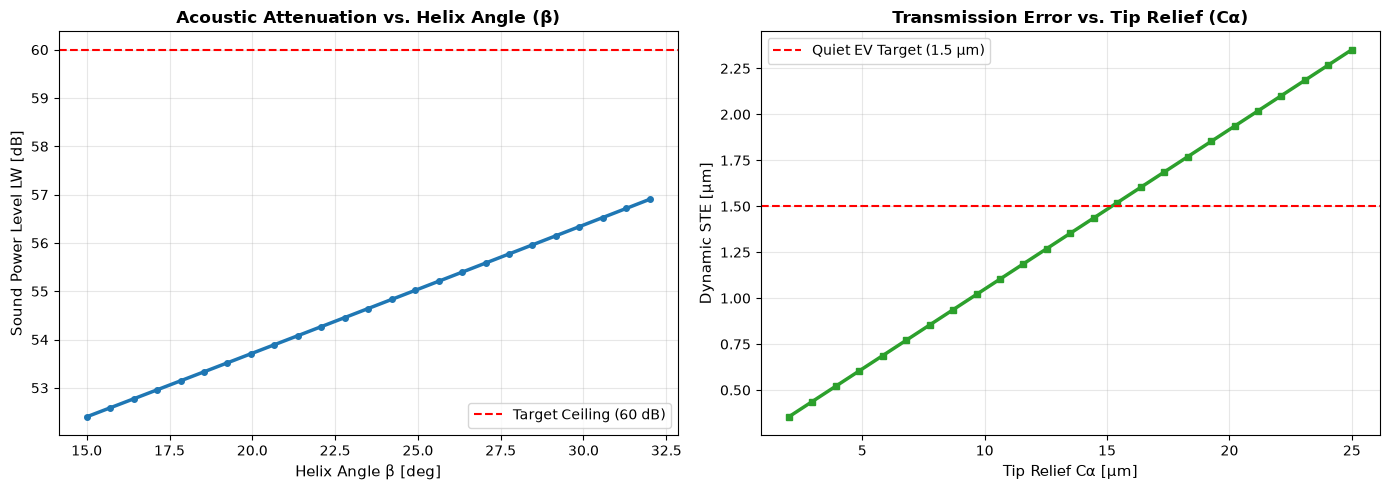


VERDICT: STAGE 3 SENSITIVITY ENGINE COMPLETE. READY FOR STAGE 4.


In [6]:
# Cell 5: Visualization of Key NVH Trade-Off Curves
beta_range = np.linspace(15.0, 32.0, 25)
calpha_range = np.linspace(2.0, 25.0, 25)

sound_beta = []
te_calpha = []

for b_val in beta_range:
    temp_deck = dict(test_deck_1)
    temp_deck['beta'] = b_val
    _, _, s_val = evaluate_forward_point(temp_deck)
    sound_beta.append(s_val)

for ca_val in calpha_range:
    temp_deck = dict(test_deck_1)
    temp_deck['Calpha'] = ca_val
    _, te_val, _ = evaluate_forward_point(temp_deck)
    te_calpha.append(te_val)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Beta vs Sound
ax1.plot(beta_range, sound_beta, color='#1f77b4', lw=2.5, marker='o', markersize=4)
ax1.axhline(60.0, color='r', linestyle='--', label='Target Ceiling (60 dB)')
ax1.set_title('Acoustic Attenuation vs. Helix Angle (β)', fontsize=12, fontweight='bold')
ax1.set_xlabel('Helix Angle β [deg]', fontsize=11)
ax1.set_ylabel('Sound Power Level LW [dB]', fontsize=11)
ax1.grid(True, alpha=0.3)
ax1.legend()

# Plot 2: Calpha vs TE
ax2.plot(calpha_range, te_calpha, color='#2ca02c', lw=2.5, marker='s', markersize=4)
ax2.axhline(1.5, color='r', linestyle='--', label='Quiet EV Target (1.5 µm)')
ax2.set_title('Transmission Error vs. Tip Relief (Cα)', fontsize=12, fontweight='bold')
ax2.set_xlabel('Tip Relief Cα [µm]', fontsize=11)
ax2.set_ylabel('Dynamic STE [µm]', fontsize=11)
ax2.grid(True, alpha=0.3)
ax2.legend()

plt.tight_layout()
plt.show()

print("\nVERDICT: STAGE 3 SENSITIVITY ENGINE COMPLETE. READY FOR STAGE 4.")
